In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("data/analysedaten_SC1.csv")
df["hat_note"] = df["note_mittel"].notna()
d = df[df["hat_note"]].copy()          # Analysegruppe: Familien mit Note
df["p731110_lbl"] = df["p731110_lbl"].str.rstrip(", ")       # Komma am Ende entfernen

lbl = {2: "höchstens Mittlere Reife/\nBerufsausbildung", 3: "(Fach-)Abitur", 4: "Meister/Hochschule"}
reihenfolge = [lbl[k] for k in (2, 3, 4)]
d["bildung_lbl"] = d["bildung_3"].map(lbl)

print("Gesamt:", len(df), "| mit Note:", len(d))
variablen = ["note_mittel", "bildung_eltern", "hisei", "einkommen_klasse", "aeq_einkommen"]
display(d[variablen].describe().round(2))
print(d[variablen].isna().mean().round(3))

Gesamt: 3481 | mit Note: 1651


,note_mittel,bildung_eltern,hisei,einkommen_klasse,aeq_einkommen
count,1651.00,1651.00,1627.00,1520.00,1520.00
mean,2.22,3.62,66.51,6.09,2040.44
std,0.73,0.71,17.80,1.67,746.72
min,1.00,1.00,12.01,1.00,223.61
25%,1.50,3.00,56.00,5.00,1587.71
50%,2.00,4.00,72.94,6.00,2020.73
75%,2.50,4.00,79.74,7.00,2598.08
max,5.00,4.00,88.96,9.00,4041.45


note_mittel         0.000
bildung_eltern      0.000
hisei               0.015
einkommen_klasse    0.079
aeq_einkommen       0.079
dtype: float64


hat_note                                     False  True 
bildung_3                                                
(Fach-)Abitur                                0.596  0.404
Meister/Hochschule                           0.427  0.573
höchstens Mittlere Reife/\nBerufsausbildung  0.750  0.250


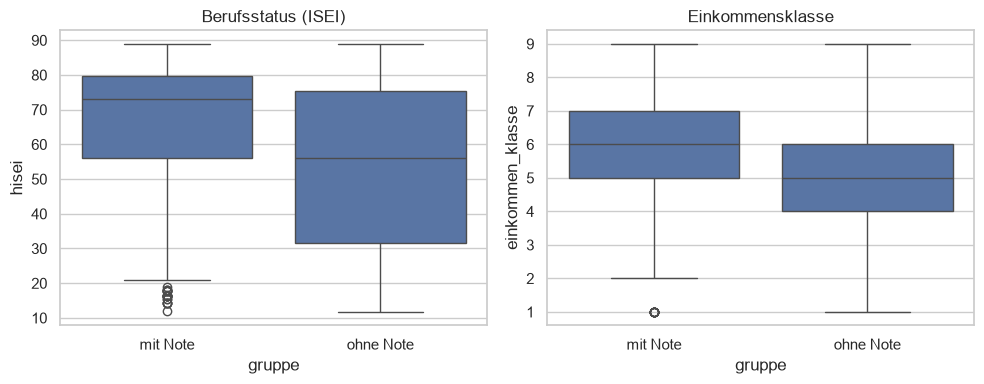

In [3]:
# 
print(pd.crosstab(df["bildung_3"].map(lbl), df["hat_note"], normalize="index").round(3))

df["gruppe"] = np.where(df["hat_note"], "mit Note", "ohne Note")
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=df, x="gruppe", y="hisei", ax=ax[0])
sns.boxplot(data=df, x="gruppe", y="einkommen_klasse", ax=ax[1])
ax[0].set_title("Berufsstatus (ISEI)")
ax[1].set_title("Einkommensklasse")
plt.tight_layout()
plt.show()

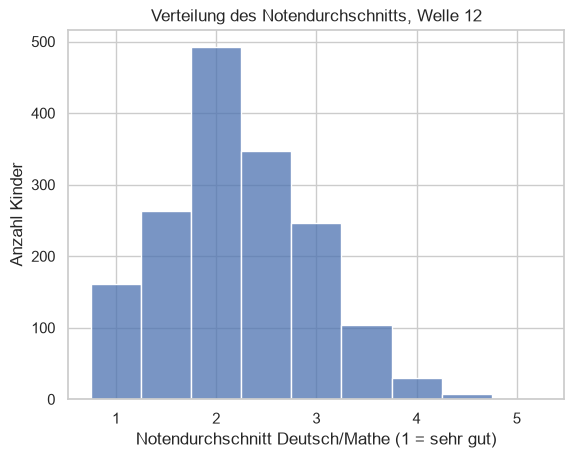

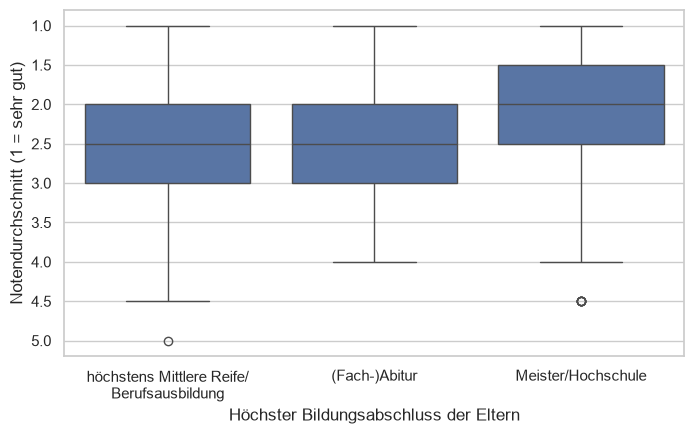

,count,mean,median,std
bildung_lbl,,,,
höchstens Mittlere Reife/\nBerufsausbildung,193,2.53,2.5,0.76
(Fach-)Abitur,224,2.32,2.5,0.76
Meister/Hochschule,1234,2.15,2.0,0.71


In [4]:
sns.histplot(d["note_mittel"], bins=np.arange(0.75, 5.5, 0.5))
plt.xlabel("Notendurchschnitt Deutsch/Mathe (1 = sehr gut)")
plt.ylabel("Anzahl Kinder")
plt.title("Verteilung des Notendurchschnitts, Welle 12")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=d, x="bildung_lbl", y="note_mittel", order=reihenfolge, ax=ax)
ax.invert_yaxis()                       # beste Note oben
ax.set_xlabel("Höchster Bildungsabschluss der Eltern")
ax.set_ylabel("Notendurchschnitt (1 = sehr gut)")
plt.show()

display(d.groupby("bildung_lbl")["note_mittel"].agg(["count", "mean", "median", "std"])
        .reindex(reihenfolge).round(2))

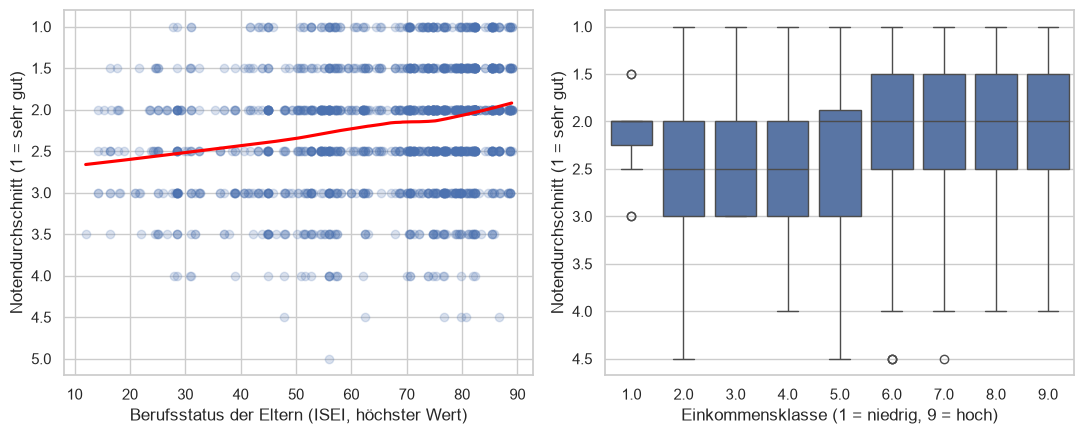

,note_gut,bildung_eltern,hisei,einkommen_klasse
note_gut,1.00,0.16,0.21,0.09
bildung_eltern,0.16,1.00,0.54,0.34
hisei,0.21,0.54,1.00,0.42
einkommen_klasse,0.09,0.34,0.42,1.00


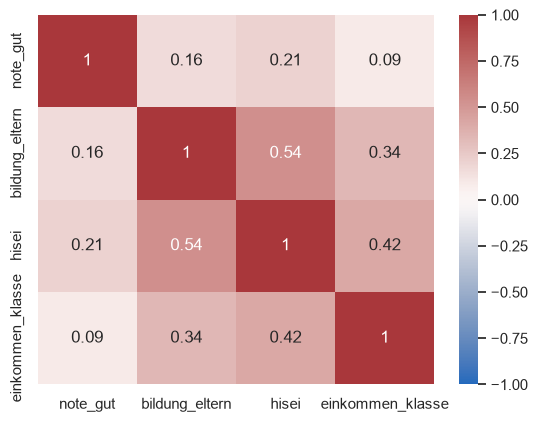

,count,mean
p700010_lbl,,
[m] männlich,834,2.31
[w] weiblich,817,2.13


,count,mean
p400500_g3_lbl,,
"Ausland, aber keiner spezifischen Herkunftsgruppe zuordenbar",71,2.18
Deutschland,1052,2.20
Italien,18,2.00
"Mittel- und Südamerika, Karibik",23,2.28
Nord- und Westeuropa,75,2.07
Nordamerika,6,1.92
Ozeanien/Polynesien,1,2.50
Polen,87,2.30
Rumänien,16,2.12


,count,mean
p731110_lbl,,
"geschieden,",30,2.30
"ledig,",386,2.23
oder leben Sie in einer eingetragenen Lebenspartnerschaft?,10,2.35
"verheiratet und leben getrennt von Ihrer Ehepartnerin / Ihrem Ehepartner,",6,2.50
"verheiratet und leben mit Ihrer Ehepartnerin / Ihrem Ehepartner zusammen,",1213,2.21
"verwitwet,",4,2.12


,count,mean
p751001_g2_lbl,,
Baden-Württemberg,173,2.13
Bayern,241,2.55
Berlin (Gesamt),177,2.05
Brandenburg,7,2.00
Bremen,27,2.22
Hamburg,126,2.18
Hessen,122,2.16
Mecklenburg-Vorpommern,32,2.17
Niedersachsen,93,2.34


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
sns.regplot(data=d, x="hisei", y="note_mittel", lowess=True,
            scatter_kws={"alpha": 0.2}, line_kws={"color": "red"}, ax=ax[0])
sns.boxplot(data=d, x="einkommen_klasse", y="note_mittel", ax=ax[1])
for a in ax:
    a.invert_yaxis()
    a.set_ylabel("Notendurchschnitt (1 = sehr gut)")
ax[0].set_xlabel("Berufsstatus der Eltern (ISEI, höchster Wert)")
ax[1].set_xlabel("Einkommensklasse (1 = niedrig, 9 = hoch)")
plt.tight_layout()
plt.show()

# Korrelationen (Spearman, weil Noten und Klassen ordinal sind); note_gut: höher = besser
kor = d[["note_gut", "bildung_eltern", "hisei", "einkommen_klasse"]].corr(method="spearman").round(2)
display(kor)
sns.heatmap(kor, annot=True, cmap="vlag", vmin=-1, vmax=1)
plt.show()

# Kontrollvariablen
for v in ["p700010_lbl", "p400500_g3_lbl", "p731110_lbl", "p751001_g2_lbl"]:
    display(d.groupby(v)["note_mittel"].agg(["count", "mean"]).round(2))

## Was zeigt das?

moderater aber stabiler Einfluss

Bundesland große Notenunterschiede --> muss unbedingt in Modell rein

Familienstand kein richtiger Einfluss --> kann raus